[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/09_design_optimisation.ipynb)

# 09 · Design optimisation: choosing stage cuts and pressures

Earlier notebooks set the stage cuts by hand. Here the toolkit chooses them.

* `stage_cut_for_spec` finds the stage cut of **one stage** that meets one specification
  (a purity or a recovery). It is a scalar root-find and takes about a second.
* `optimise` handles **any layout and several variables**. It minimises cost per tonne,
  membrane area, power or specific energy, subject to a minimum purity and recovery of a product.

The case is biogas upgrading at Makaruk et al. (2010) conditions: 40 % CO₂ / 60 % CH₄,
1 000 Nm³/h, polyimide membrane with α = 35, target 98 % CH₄ in the retentate product.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


In [2]:
m  = Membrane(MEMBRANE_PRESETS["Polyimide CO2/CH4, a=35 (Makaruk 2010)"])
xf = FEED_PRESETS["biogas, 60% CH4 (Makaruk 2010)"]
F  = nm3h_to_mols(1000)

## 1. One stage, one specification

What stage cut gives 98 % CH₄ in the retentate, for each flow pattern? The answer fixes the
methane recovery, which a single stage cannot choose independently.

In [3]:
rows = []
for pat in PATTERNS:
    try:
        r = stage_cut_for_spec(m, xf, "CH4", 0.98, p_high=10, p_low=1, pattern=pat,
                               stream="retentate", spec="purity", feed_flow=F)
        rows.append({"pattern": LABELS[pat], "stage cut": r.theta,
                     "CH4 recovery": r.recovery("CH4", "retentate"), "area m2": r.area})
    except InfeasibleError as e:
        rows.append({"pattern": LABELS[pat], "note": str(e)})
pd.DataFrame(rows).set_index("pattern")

,note,stage cut,CH4 recovery,area m2
pattern,,,,
Well-mixed,CH4 purity of 0.98 in the retentate is not rea...,NaN,NaN,NaN
Cross-flow,NaN,0.5330,0.7628,2210.8521
Co-current,CH4 purity of 0.98 in the retentate is not rea...,NaN,NaN,NaN
Counter-current,NaN,0.4999,0.8168,1743.6240


Only cross-flow and counter-current stages reach 98 % at a pressure ratio of 10. In a well-mixed
stage the whole permeate side sees the retentate composition, and in a co-current stage the
permeate-side CO₂ builds up along the module; in both, the driving force for CO₂ vanishes before the
retentate is pure enough. `stage_cut_for_spec` reports the reachable range instead of failing
silently.

Even the stages that reach the target lose 18–24 % of the methane. A recovery target therefore
needs a cascade, and a cascade has several stage cuts and pressures to choose: that is the job of
`optimise`.

## 2. Several variables: a two-stage stripping cascade

Write a small function that builds the flowsheet from the variables you want to choose. Here:
the two stage cuts and the feed pressure, with cross-flow stages and a 1 bar permeate.

In [4]:
def design(theta1, theta2, p_high):
    return two_stage_stripping(m, xf, F,
                               StageSpec(theta1, p_high, 1.0, "cross_flow"),
                               StageSpec(theta2, p_high, 1.0, "cross_flow"))

bounds = {"theta1": (0.15, 0.6), "theta2": (0.15, 0.7), "p_high": (5.0, 20.0)}
best = optimise(design, bounds, product="slow-gas product", component="CH4",
                purity=0.98, recovery=0.97, objective="cost")
print(best.summary())

optimum (feasible; 72 flowsheet evaluations): SLSQP: Optimization terminated successfully
  theta1 = 0.2905, theta2 = 0.4013, p_high = 20
  cost = 69.56 USD/t; purity 0.9800, recovery 0.9700
  total area 924.6 m2, total power 192.5 kW, recycle/feed 0.398


`optimise` first scans the design space with a quasi-random (Sobol) sample, then refines the best
point that meets the targets with a constrained local optimiser. Every evaluation is kept in
`best.history`, so the scan doubles as a map of the trade-off:

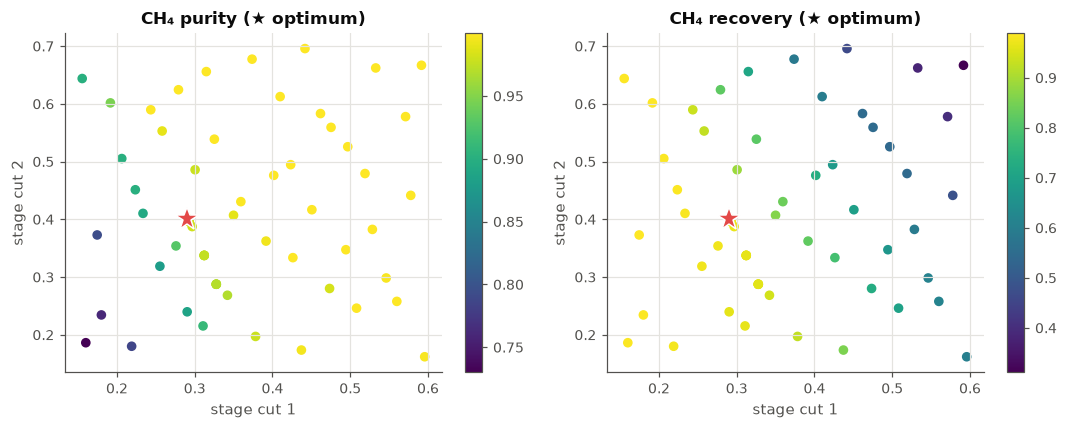

In [5]:
h = best.history[best.history["solved"]]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, col, lab in ((ax[0], "purity", "CH₄ purity"), (ax[1], "recovery", "CH₄ recovery")):
    sc = a.scatter(h["theta1"], h["theta2"], c=h[col], cmap="viridis", s=28)
    a.plot(best.variables["theta1"], best.variables["theta2"], "*", color="#e34948", ms=16,
           mec="white")
    a.set_xlabel("stage cut 1"); a.set_ylabel("stage cut 2"); a.set_title(f"{lab} (★ optimum)")
    fig.colorbar(sc, ax=a)
plt.tight_layout()

## 3. The optimum depends on the prices

With two active constraints (purity and recovery) and three variables, one degree of freedom is
left, and the cost assumptions decide where it goes. Cheap electricity favours a high feed
pressure (less membrane); expensive electricity favours a lower pressure and more membrane.

The defaults in `CostAssumptions` are placeholders, so treat the numbers as an illustration of the
trend, not as prices. Each optimisation below starts from the previous optimum (`x0`) with a short
scan, which keeps it quick.

In [6]:
rows, x0 = [], best.variables
for price in (0.05, 0.10, 0.20, 0.30):
    ca = CostAssumptions(electricity_per_kWh=price)
    o = optimise(design, bounds, "slow-gas product", "CH4", purity=0.98, recovery=0.97,
                 objective="cost", ca=ca, x0=x0, n_scan=8)
    x0 = o.variables
    rows.append({"electricity USD/kWh": price, **o.variables, "USD/t CH4": o.value,
                 "area m2": o.result.total_area, "power kW": o.result.total_power_kW,
                 "feasible": o.feasible})
pd.DataFrame(rows).set_index("electricity USD/kWh")

,theta1,theta2,p_high,USD/t CH4,area m2,power kW,feasible
electricity USD/kWh,,,,,,,
0.05,0.2905,0.4013,20.000,46.4504,924.5672,192.5076,True
0.10,0.2905,0.4013,20.000,69.5566,924.5672,192.5076,True
0.20,0.2844,0.4187,16.910,114.9659,1203.8257,184.3453,True
0.30,0.2827,0.4236,16.212,158.8100,1289.8283,182.3983,True


## 4. Other objectives and your own layouts

* `objective="area"`, `"power"` or `"energy"` (kWh per tonne), or any function of the flowsheet
  result, e.g. `objective=lambda r: r.total_area + 5 * r.total_power_kW`.
* `product` takes a product label (`"slow-gas product"`, `"fast-gas product"`) or any stream name.
* The design function can build any layout (single stage, three-stage, a sweep on one stage) and
  expose any variable: pressures, stage cuts, flow patterns fixed inside it.

The optimiser finds a *local* optimum from the best scanned point. For an important design, check
`history` or repeat with a larger `n_scan` and a different `seed`.